In [4]:
import subprocess
import json
import os
import tempfile
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [5]:
def run(cmd, N, relator_length=None):
    with tempfile.TemporaryDirectory() as tmp:
        out = os.path.join(tmp, "results.json")
        args = cmd + ["-p", "ms_9_9.json",
                      "--max-nodes", str(N),
                      "--out", out]
        if relator_length is not None:
            args += ["--max-len", str(relator_length)]
        subprocess.run(args, check=True, stdout=subprocess.DEVNULL)
        with open(out) as f:
            return json.load(f)

In [6]:
substitution_1000 = run(["../cpp_ports/substitution"], 1000)
print(f"substitution 1000 done: {len(substitution_1000)} solved")
greedy_1000 = run(["../cpp_ports/greedy_search"], 1000)
print(f"greedy 1000 done: {len(greedy_1000)} solved")
bfs_1000 = run(["../cpp_ports/breadth_first_search"], 1000)
print(f"bfs 1000 done: {len(bfs_1000)} solved")

substitution_10000 = run(["../cpp_ports/substitution"], 10000)
print(f"substitution 10000 done: {len(substitution_10000)} solved")
greedy_10000 = run(["../cpp_ports/greedy_search"], 10000)
print(f"greedy 10000 done: {len(greedy_10000)} solved")
bfs_10000 = run(["../cpp_ports/breadth_first_search"], 10000)
print(f"bfs 10000 done: {len(bfs_10000)} solved")

substitution_100000 = run(["../cpp_ports/substitution"], 100000)
print(f"substitution 100000 done: {len(substitution_100000)} solved")
greedy_100000 = run(["../cpp_ports/greedy_search"], 100000)
print(f"greedy 100000 done: {len(greedy_100000)} solved")
bfs_100000 = run(["../cpp_ports/breadth_first_search"], 100000)
print(f"bfs 100000 done: {len(bfs_100000)} solved")

greedy_10000_40 = run(["../cpp_ports/greedy_search"], 10000, 40)
print(f"greedy 10000 40 done: {len(greedy_10000_40)} solved")
bfs_10000_40 = run(["../cpp_ports/breadth_first_search"], 10000, 40)
print(f"bfs 10000 40 done: {len(bfs_10000_40)} solved")

greedy_100000_40 = run(["../cpp_ports/greedy_search"], 100000, 40)
print(f"greedy 100000 40 done: {len(greedy_100000_40)} solved")
bfs_100000_40 = run(["../cpp_ports/breadth_first_search"], 100000, 40)
print(f"bfs 100000 40 done: {len(bfs_100000_40)} solved")

greedy_100000_20 = run(["../cpp_ports/greedy_search"], 100000, 20)
print(f"greedy 100000 20 done: {len(greedy_100000_20)} solved")
bfs_100000_20 = run(["../cpp_ports/breadth_first_search"], 100000, 20)
print(f"bfs 100000 20 done: {len(bfs_100000_20)} solved")

substitution 1000 done: 1610 solved
greedy 1000 done: 1001 solved
bfs 1000 done: 0 solved
substitution 10000 done: 1934 solved
greedy 10000 done: 1482 solved
bfs 10000 done: 1 solved
substitution 100000 done: 2309 solved
greedy 100000 done: 1888 solved
bfs 100000 done: 5 solved
greedy 10000 40 done: 1482 solved
bfs 10000 40 done: 1 solved
greedy 100000 40 done: 1888 solved
bfs 100000 40 done: 5 solved
greedy 100000 20 done: 1876 solved
bfs 100000 20 done: 7 solved


In [7]:
import math

with open("ms_9_9.json") as f:
    presentations = json.load(f)

NO_LIMIT = math.inf   # max_len value for runs without --max-len

def len_label(L):
    return "none" if L == NO_LIMIT else str(L)

# keys are (algorithm, max_nodes, max_len)
results = {
    ("substitution", 1000, NO_LIMIT): substitution_1000,
    ("greedy", 1000, NO_LIMIT): greedy_1000,
    ("bfs", 1000, NO_LIMIT): bfs_1000,
    ("substitution", 10000, NO_LIMIT): substitution_10000,
    ("greedy", 10000, NO_LIMIT): greedy_10000,
    ("bfs", 10000, NO_LIMIT): bfs_10000,
    ("substitution", 100000, NO_LIMIT): substitution_100000,
    ("greedy", 100000, NO_LIMIT): greedy_100000,
    ("bfs", 100000, NO_LIMIT): bfs_100000,
    ("greedy", 10000, 40): greedy_10000_40,
    ("bfs", 10000, 40): bfs_10000_40,
    ("greedy", 100000, 40): greedy_100000_40,
    ("bfs", 100000, 40): bfs_100000_40,
    ("greedy", 100000, 20): greedy_100000_20,
    ("bfs", 100000, 20): bfs_100000_20,
}

rows = []
for (algo, N, L), res in results.items():
    for i, p in enumerate(presentations):
        key = str(i)
        solved = key in res
        rows.append({
            "idx": i,
            "n": p["n"],
            "w_len": len(p["w"]),
            "algorithm": algo,
            "max_nodes": N,
            "max_len": L,
            "solved": solved,
            "path": res[key][0] if solved else None,
            "path_len": len(res[key][0]) if solved else None,
        })
df = pd.DataFrame(rows)

In [8]:
dfs = {
    (algo, N, L): df[(df.algorithm == algo) & (df.max_nodes == N) & (df.max_len == L)].reset_index(drop=True)
    for (algo, N, L) in results
}

summary = (df.groupby(["algorithm", "max_nodes", "max_len", "n", "w_len"])["solved"]
             .agg(solved="sum", total="count")
             .reset_index())
summary["unsolved"] = summary["total"] - summary["solved"]
summary["frac_solved"] = summary["solved"] / summary["total"]

algos = ["substitution", "greedy", "bfs"]
# every (max_nodes, max_len) setting that was run, with the algorithms run at it
settings = sorted({(N, L) for (_, N, L) in results})
algos_at = {(N, L): [a for a in algos if (a, N, L) in results] for (N, L) in settings}

In [9]:
for (N, L) in settings:
    if ("greedy", N, L) not in dfs or ("substitution", N, L) not in dfs:
        continue
    g = dfs[("greedy", N, L)]
    s = dfs[("substitution", N, L)]
    greedy_solved = set(g.loc[g.solved, "idx"])
    subs_solved = set(s.loc[s.solved, "idx"])
    only_greedy = sorted(greedy_solved - subs_solved)
    print(f"max_nodes={N}, max_len={len_label(L)}: {len(only_greedy)} solved by greedy but not substitution")
    print(only_greedy)

max_nodes=1000, max_len=none: 0 solved by greedy but not substitution
[]
max_nodes=10000, max_len=none: 0 solved by greedy but not substitution
[]
max_nodes=100000, max_len=none: 0 solved by greedy but not substitution
[]


In [10]:
table = pd.DataFrame({key: sub["path_len"].describe() for key, sub in dfs.items()}).T
table.index.names = ["algorithm", "max_nodes", "max_len"]
table["count"] = table["count"].astype(int)   # shows 1610, not 1610.0
table = table.sort_index().round(1)           # rows in algorithm/max_nodes/max_len order
table

count  mean   std   min   25%   50%    75%  \
algorithm    max_nodes max_len                                               
bfs          1000      inf          0   NaN   NaN   NaN   NaN   NaN    NaN   
             10000     40.0         1   4.0   NaN   4.0   4.0   4.0    4.0   
                       inf          1   4.0   NaN   4.0   4.0   4.0    4.0   
             100000    20.0         7   5.0   0.6   4.0   5.0   5.0    5.0   
                       40.0         5   4.8   0.4   4.0   5.0   5.0    5.0   
                       inf          5   4.8   0.4   4.0   5.0   5.0    5.0   
greedy       1000      inf       1001  12.9   4.2   5.0  10.0  12.0   15.0   
             10000     40.0      1482  17.6   8.3   5.0  11.0  15.0   23.0   
                       inf       1482  17.6   8.3   5.0  11.0  15.0   23.0   
             100000    20.0      1876  24.1  16.3   5.0  12.0  19.0   31.0   
                       40.0      1888  24.2  16.4   5.0  12.0  19.5   31.0   
                       inf       1888  24.2  16.4   5.0  12.0  19.5   31.0   
substitution 1000      inf       1610  50.3  29.1  11.0  30.0  41.0   61.8   
             10000     inf       1934  70.6  62.7  11.0  32.0  48.0   82.0   
             100000    inf       2309  95.5  93.6  11.0  35.0  57.0  126.0   

                                   max  
algorithm    max_nodes max_len          
bfs          1000      inf         NaN  
             10000     40.0        4.0  
                       inf         4.0  
             100000    20.0        6.0  
                       40.0        5.0  
                       inf         5.0  
greedy       1000      inf        26.0  
             10000     40.0       47.0  
                       inf        47.0  
             100000    20.0       94.0  
                       40.0      109.0  
                       inf       109.0  
substitution 1000      inf       187.0  
             10000     inf       483.0  
             100000    inf      1100.0

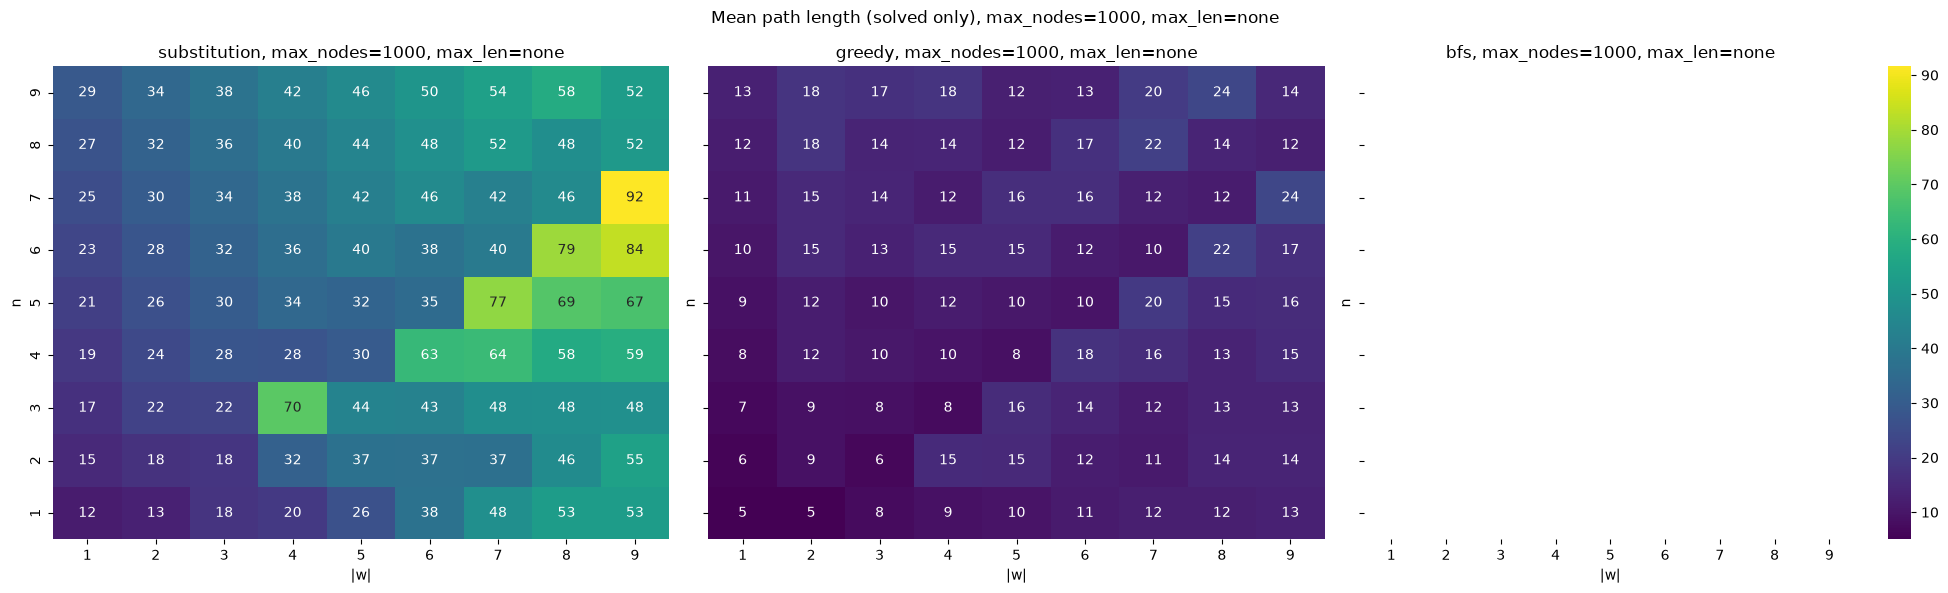

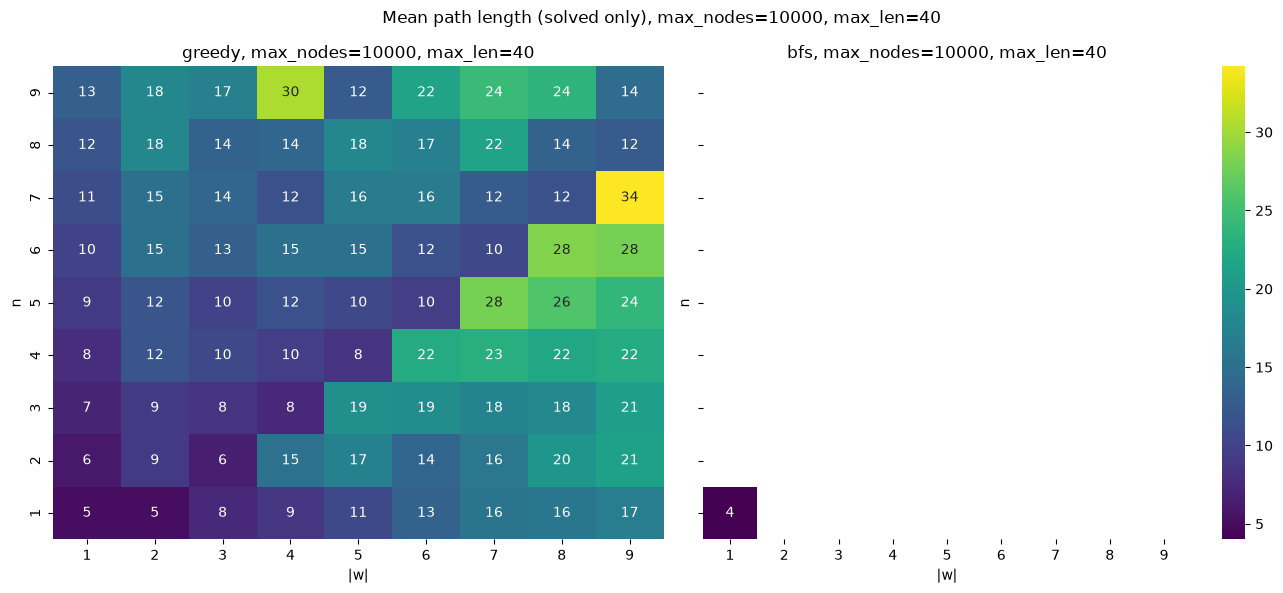

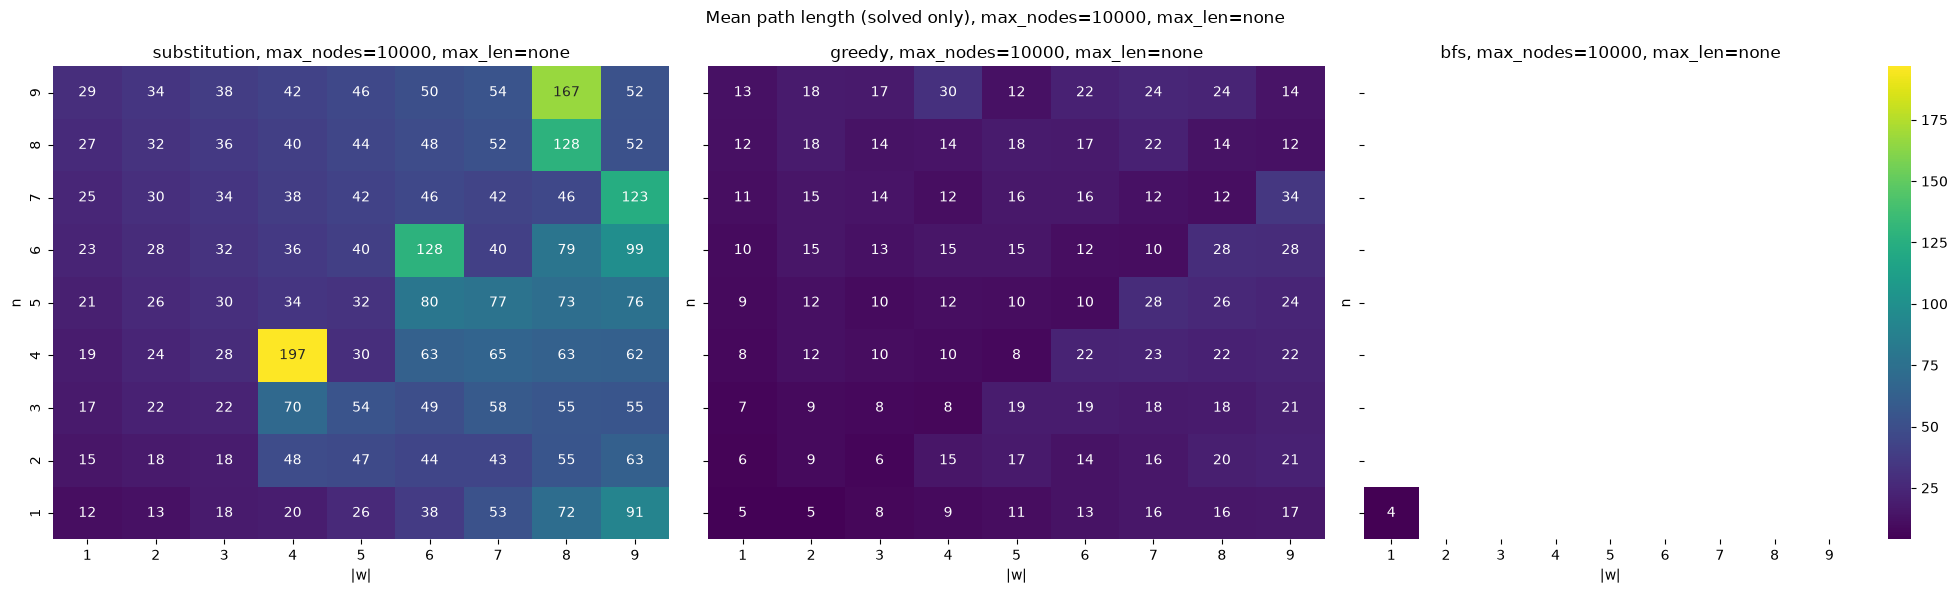

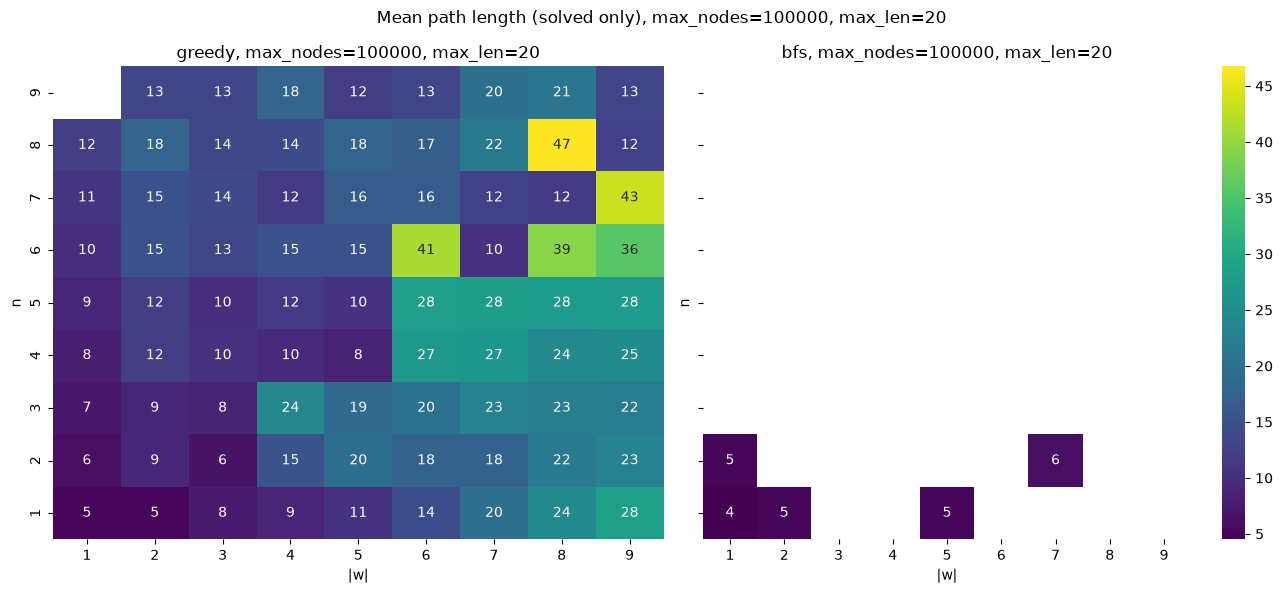

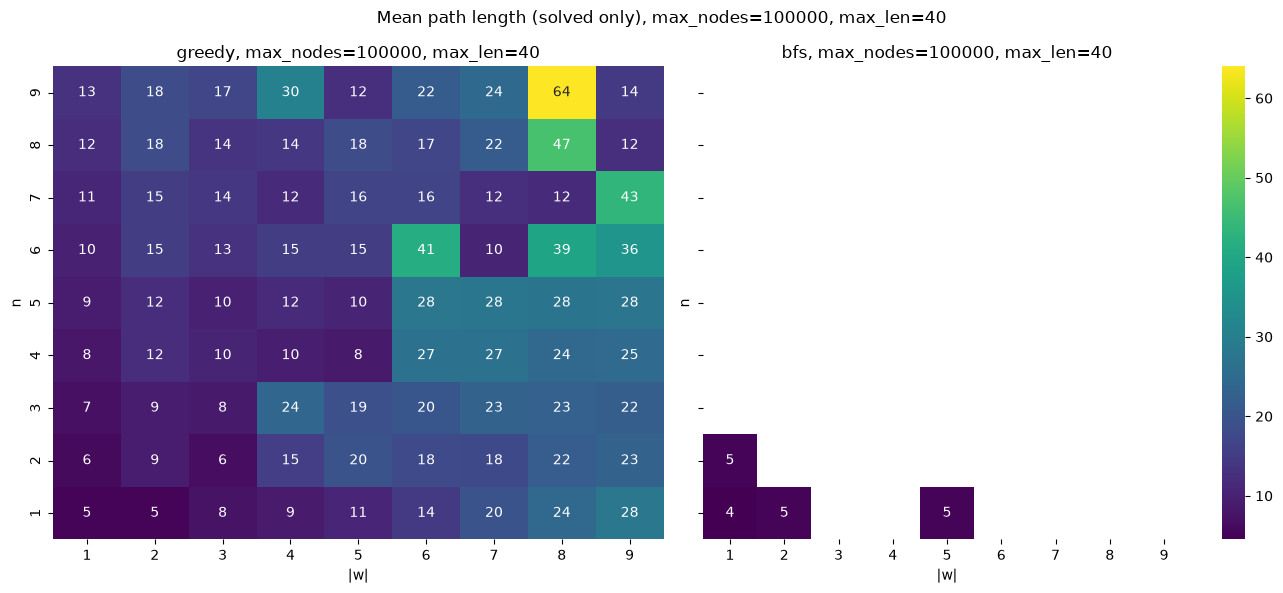

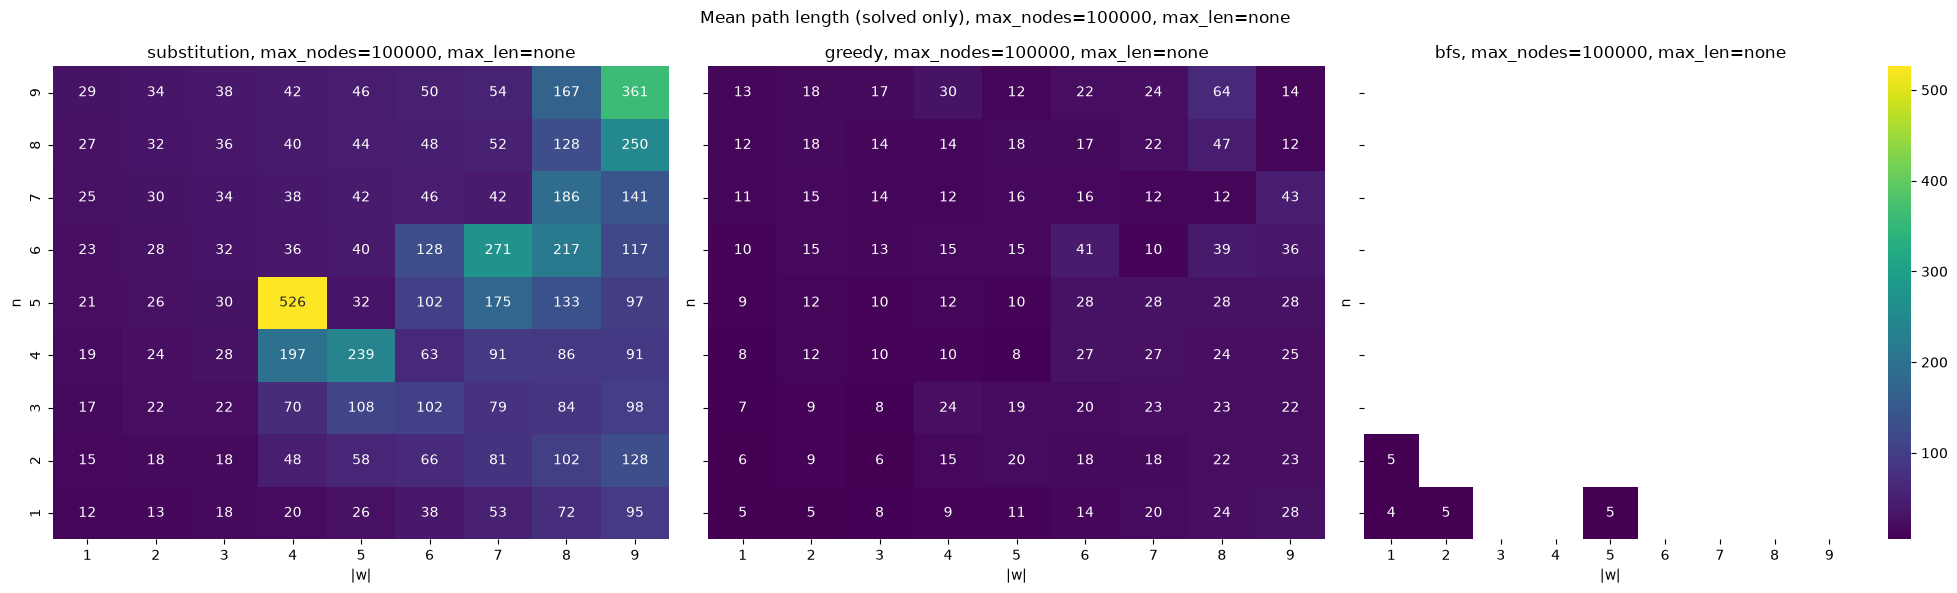

In [11]:
path_summary = (df[df.solved]
                .groupby(["algorithm", "max_nodes", "max_len", "n", "w_len"])["path_len"]
                .mean()
                .reset_index())

for (N, L) in settings:
    here = algos_at[(N, L)]
    at_NL = path_summary[(path_summary.max_nodes == N) & (path_summary.max_len == L)]
    vmin, vmax = at_NL.path_len.min(), at_NL.path_len.max()   # same scale for all plots in the row

    fig, axes = plt.subplots(1, len(here), figsize=(20 * len(here) / 3, 6), sharey=True, squeeze=False)
    for ax, algo in zip(axes[0], here):
        grid = (at_NL[at_NL.algorithm == algo]
                .pivot(index="n", columns="w_len", values="path_len")
                .reindex(index=range(1, 10), columns=range(1, 10)))
        sns.heatmap(grid, ax=ax, vmin=vmin, vmax=vmax, cmap="viridis",
                    annot=True, fmt=".0f", cbar=(algo == here[-1]))
        ax.set_title(f"{algo}, max_nodes={N}, max_len={len_label(L)}")
        ax.set_xlabel("|w|")
        ax.set_ylabel("n")
        ax.invert_yaxis()
    fig.suptitle(f"Mean path length (solved only), max_nodes={N}, max_len={len_label(L)}")
    plt.tight_layout()
    plt.show()

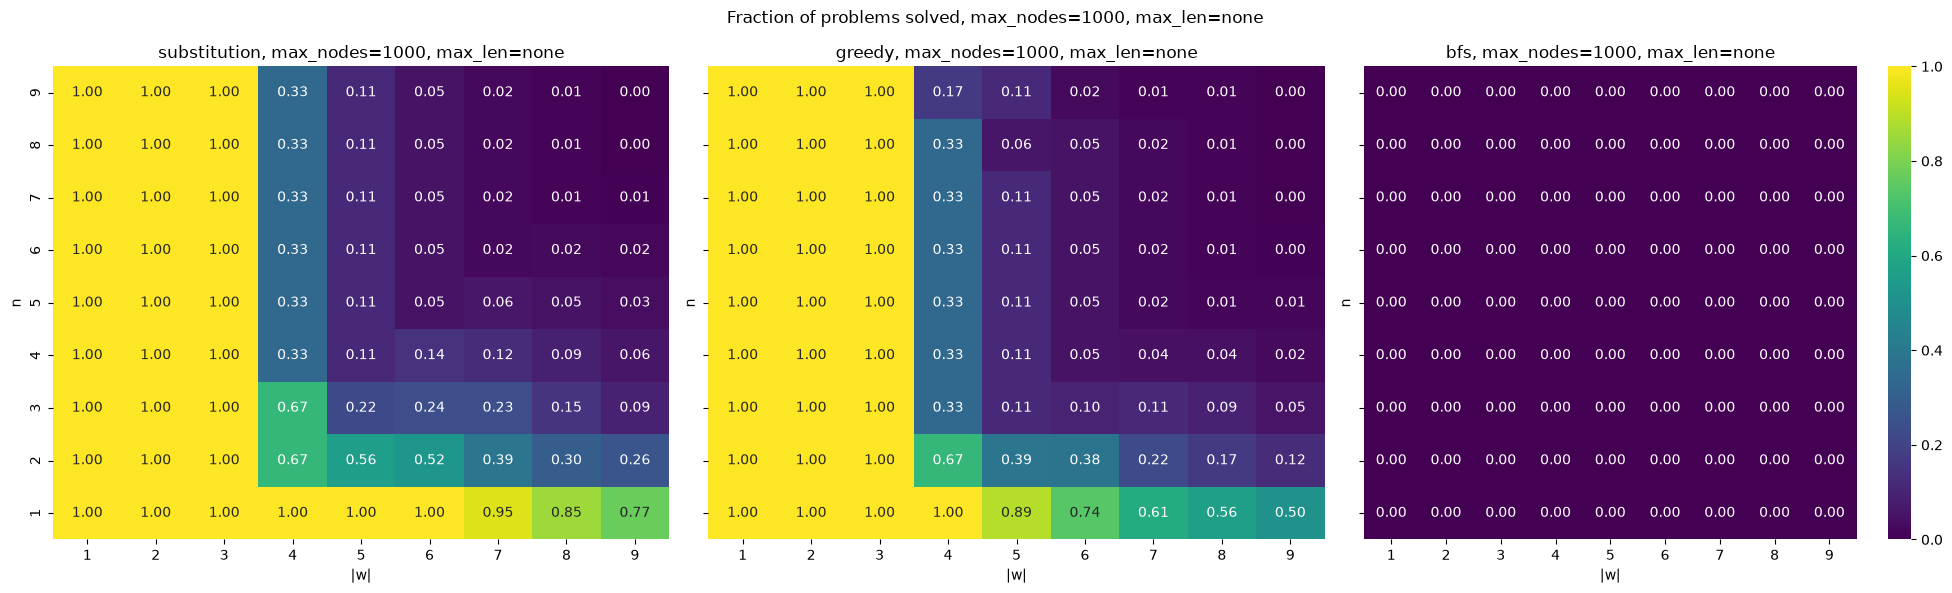

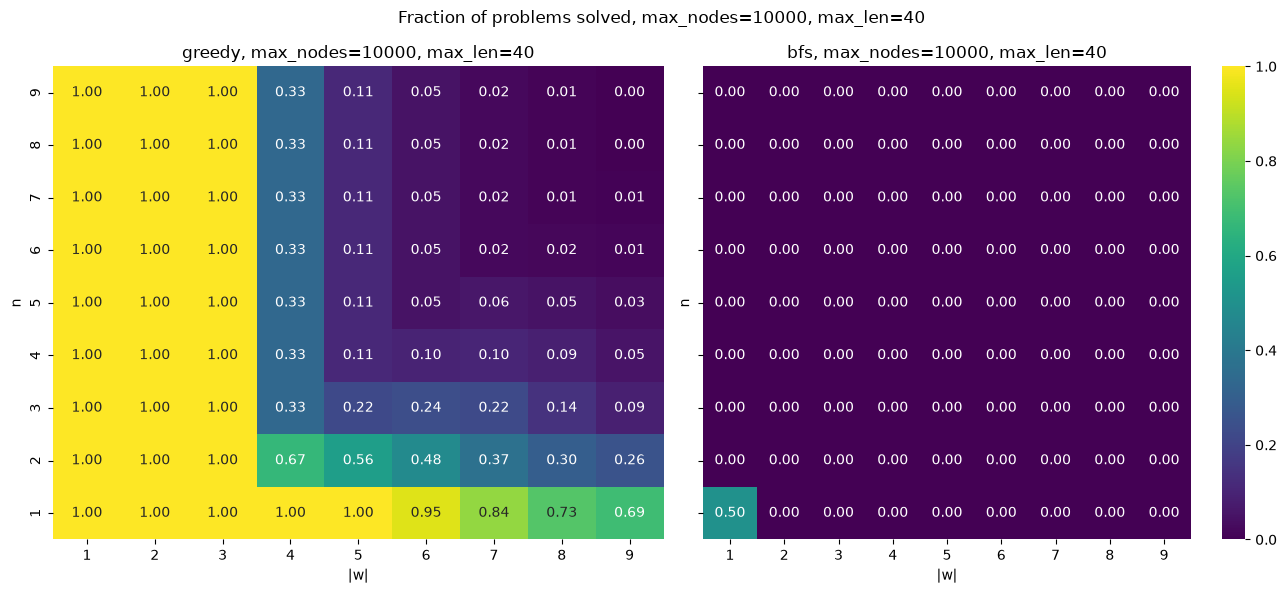

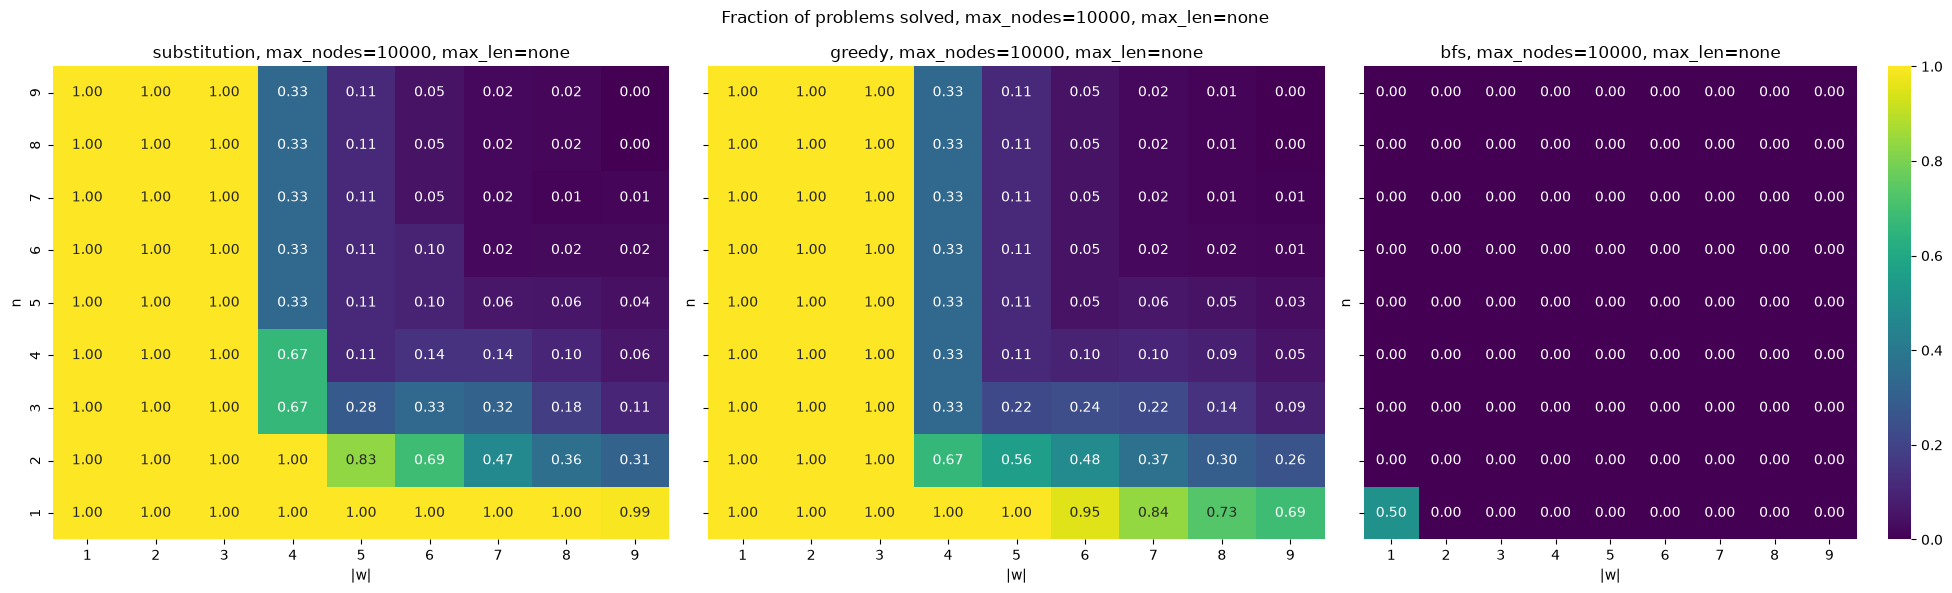

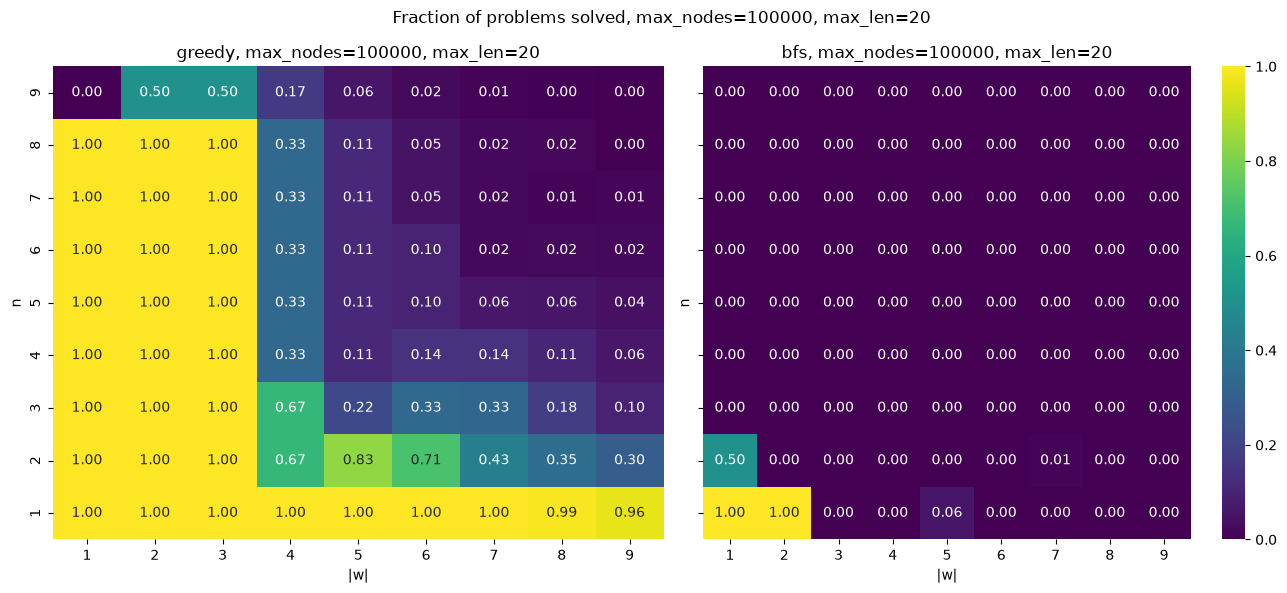

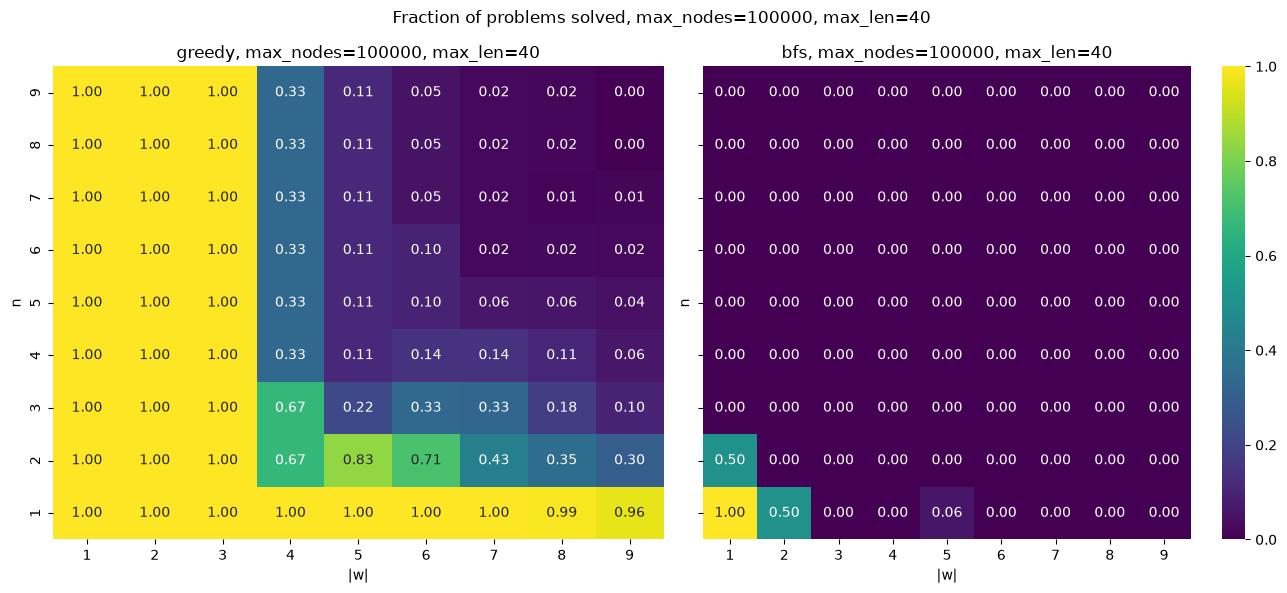

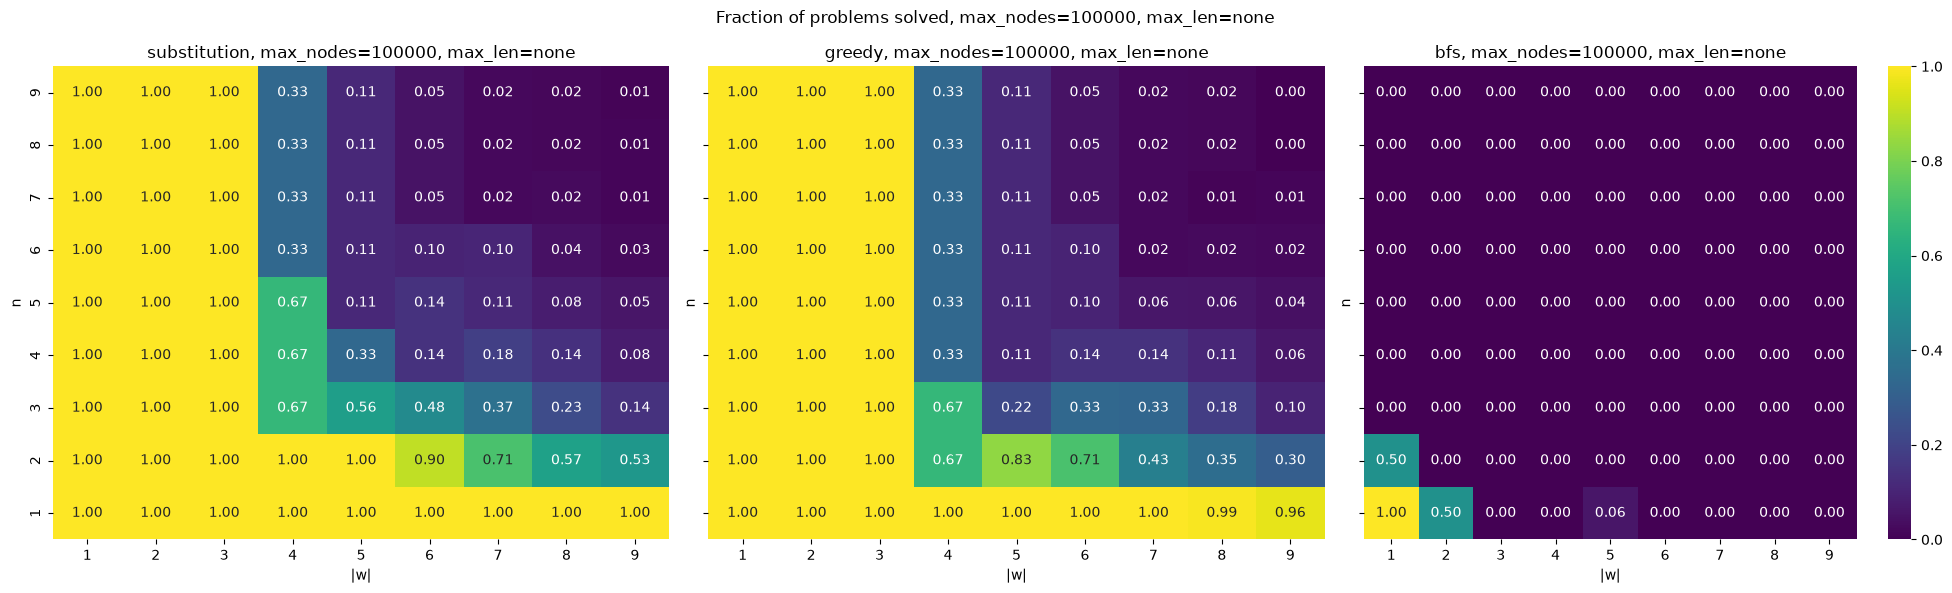

In [12]:
for (N, L) in settings:
    here = algos_at[(N, L)]
    at_NL = summary[(summary.max_nodes == N) & (summary.max_len == L)]

    fig, axes = plt.subplots(1, len(here), figsize=(20 * len(here) / 3, 6), sharey=True, squeeze=False)
    for ax, algo in zip(axes[0], here):
        grid = (at_NL[at_NL.algorithm == algo]
                .pivot(index="n", columns="w_len", values="frac_solved")
                .reindex(index=range(1, 10), columns=range(1, 10)))
        sns.heatmap(grid, ax=ax, vmin=0, vmax=1, cmap="viridis",
                    annot=True, fmt=".2f", cbar=(algo == here[-1]))
        ax.set_title(f"{algo}, max_nodes={N}, max_len={len_label(L)}")
        ax.set_xlabel("|w|")
        ax.set_ylabel("n")
        ax.invert_yaxis()
    fig.suptitle(f"Fraction of problems solved, max_nodes={N}, max_len={len_label(L)}")
    plt.tight_layout()
    plt.show()